<a href="https://colab.research.google.com/github/kananshr13/CSET-343-Ai-in-Healthcare/blob/main/Lab_Experiment_8_CSET_343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install nltk wordcloud gensim pyLDAvis seaborn

In [11]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [12]:
#dataset loading
base_url = ("https://raw.githubusercontent.com/WuraolaOyewusi/"
            "Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/")
files = [
    "Adult_Immunization_Features_Headlines.csv",
    "Adult_Immunization_News_Headlines.csv",
    "Adverse_Drug_Events_Related_Headlines.csv",
    "Adverse_Drug_Reaction_News_Headlines.csv",
]
frames = []
for f in files:
    try:
        part = pd.read_csv(base_url + f)
    except UnicodeDecodeError:
        part = pd.read_csv(base_url + f, encoding="latin-1")
    part["source_file"] = f
    frames.append(part)
    print(f, part.shape)

df = pd.concat(frames, ignore_index=True)
print("Combined shape:", df.shape)
df.head()

Adult_Immunization_Features_Headlines.csv (366, 5)
Adult_Immunization_News_Headlines.csv (1482, 5)
Adverse_Drug_Events_Related_Headlines.csv (4118, 5)
Adverse_Drug_Reaction_News_Headlines.csv (2551, 5)
Combined shape: (8517, 5)


,Date,Source,Headlines,Teaser,source_file
0,October 2004,Medscape Infectious Diseases,"Infectious Diseases: October 30, 2004","Dr. Bartlett reviews the latest on influenza, ...",Adult_Immunization_Features_Headlines.csv
1,July 2004,Journal of the American Board of Family Medicine,Influenza Vaccination in Pregnancy,Are enough family physicians and obstetricians...,Adult_Immunization_Features_Headlines.csv
2,June 2004,Medscape Nurses,Bacterial Meningitis: A Deadly But Preventable...,Those whose lives have been touched by this le...,Adult_Immunization_Features_Headlines.csv
3,April 2004,Alimentary Pharmacology & Therapeutics,Hepatitis Vaccination in Patients With Chronic...,Despite a declining incidence of acute viral h...,Adult_Immunization_Features_Headlines.csv
4,November 2003,Medscape Infectious Diseases,Emerging Infections,Dr. John Bartlett reports on the latest data f...,Adult_Immunization_Features_Headlines.csv


In [13]:
print(df.columns.tolist())
print(df.isnull().sum())

['Date', 'Source', 'Headlines', 'Teaser', 'source_file']
Date           0
Source         0
Headlines      0
Teaser         0
source_file    0
dtype: int64


In [14]:
text_col = None

if text_col is None:
    for c in df.columns:
        if any(k in c.lower() for k in ['headline', 'title', 'text', 'teaser']):
            text_col = c
            break

if text_col is None:
    text_col = df.select_dtypes(include='object').columns[0]

print("Using column:", text_col)

df = df.dropna(subset=[text_col]).drop_duplicates(subset=[text_col]).reset_index(drop=True)
print("Rows after dropping nulls/duplicates:", len(df))

Using column: Headlines
Rows after dropping nulls/duplicates: 5856


In [15]:
stop_words = set(stopwords.words('english'))

stop_words.update(['say', 'says', 'new', 'may', 'could', 'one', 'also', 'get', 'would'])

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()                                          # lowercase
    text = re.sub(r'http\S+|www\S+', ' ', text)                       # remove links
    text = text.translate(str.maketrans('', '', string.punctuation))  # punctuation
    text = re.sub(r'\d+', ' ', text)                                  # numbers
    tokens = word_tokenize(text)                                      # tokenize
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]  # stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]                # lemmatize
    return tokens

In [16]:
df['tokens'] = df[text_col].apply(clean_text)
df['clean_text'] = df['tokens'].apply(lambda x: " ".join(x))

# drop rows that became empty after cleaning
df = df[df['tokens'].str.len() > 0].reset_index(drop=True)

for i in range(5):
    print("Original :", df[text_col][i])
    print("Cleaned  :", df['clean_text'][i])
    print("-" * 60)

Original : Infectious Diseases: October 30, 2004
Cleaned  : infectious disease october
------------------------------------------------------------
Original : Influenza Vaccination in Pregnancy
Cleaned  : influenza vaccination pregnancy
------------------------------------------------------------
Original : Bacterial Meningitis: A Deadly But Preventable Disease
Cleaned  : bacterial meningitis deadly preventable disease
------------------------------------------------------------
Original : Hepatitis Vaccination in Patients With Chronic Liver Disease
Cleaned  : hepatitis vaccination patient chronic liver disease
------------------------------------------------------------
Original : Emerging Infections
Cleaned  : emerging infection
------------------------------------------------------------


In [17]:
all_words = [w for toks in df['tokens'] for w in toks]
word_freq = Counter(all_words)

print("Total tokens:", len(all_words))
print("Unique words:", len(word_freq))
word_freq.most_common(20)

Total tokens: 33343
Unique words: 6882


[('vaccine', 884),
 ('risk', 463),
 ('drug', 455),
 ('fda', 447),
 ('cancer', 408),
 ('patient', 366),
 ('flu', 268),
 ('vaccination', 212),
 ('use', 207),
 ('influenza', 196),
 ('treatment', 190),
 ('hpv', 184),
 ('linked', 182),
 ('therapy', 180),
 ('safety', 156),
 ('adverse', 146),
 ('disease', 144),
 ('effect', 128),
 ('child', 126),
 ('safe', 121)]

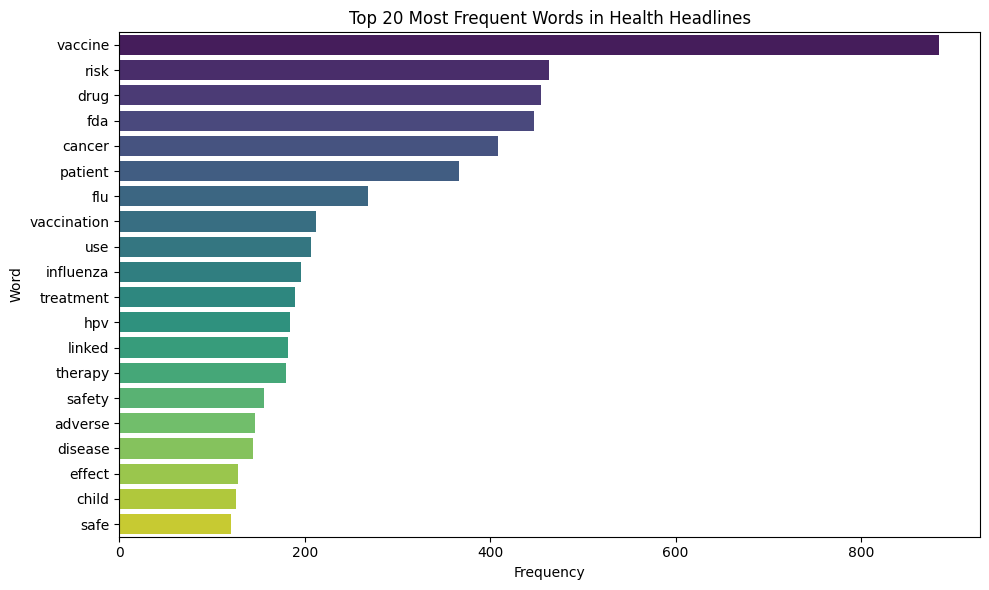

In [18]:
top20 = pd.DataFrame(word_freq.most_common(20), columns=['word', 'count'])

plt.figure(figsize=(10, 6))
sns.barplot(data=top20, x='count', y='word', hue='word', palette='viridis', legend=False)
plt.title("Top 20 Most Frequent Words in Health Headlines")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

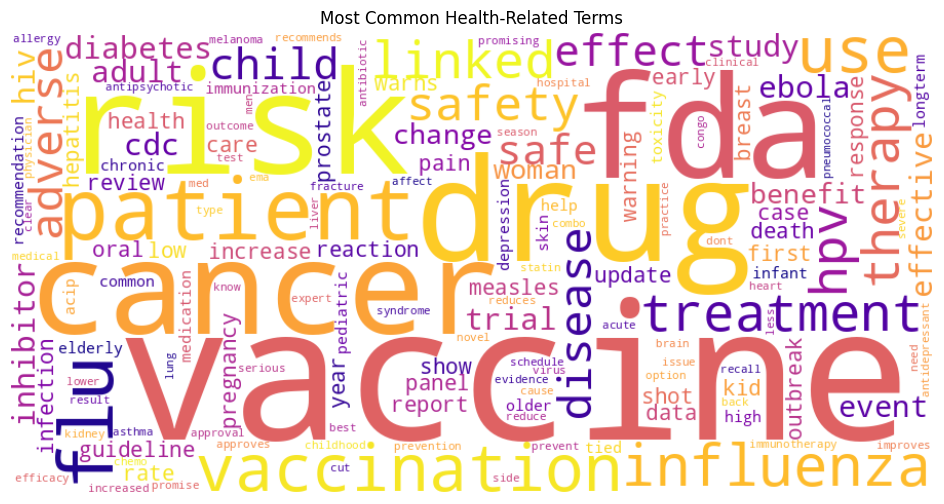

In [19]:
wc = WordCloud(width=900, height=450, background_color='white',
               max_words=150, colormap='plasma').generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Most Common Health-Related Terms")
plt.show()

In [20]:
from gensim import corpora
from gensim.models import LdaModel

dictionary = corpora.Dictionary(df['tokens'])
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(toks) for toks in df['tokens']]
print("Vocabulary size:", len(dictionary))
print("Documents:", len(corpus))

Vocabulary size: 1264
Documents: 5856


In [21]:
num_topics = 5

lda_model = LdaModel(corpus=corpus,
                     id2word=dictionary,
                     num_topics=num_topics,
                     random_state=42,
                     passes=10,
                     alpha='auto',
                     per_word_topics=True)

In [22]:
for idx in range(num_topics):
    words = lda_model.show_topic(idx, topn=5)
    print(f"Topic {idx + 1}:", ", ".join(w for w, _ in words))

Topic 1: vaccine, vaccination, hpv, influenza, ebola
Topic 2: risk, cancer, linked, use, effect
Topic 3: cancer, vaccine, flu, patient, inhibitor
Topic 4: patient, risk, therapy, vaccine, trial
Topic 5: fda, drug, safety, adverse, diabetes


In [23]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, corpus, dictionary)
vis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.262299 -0.127053       1        1  21.947137
2     -0.124835  0.109492       2        1  19.965603
4      0.192783 -0.213397       3        1  19.860212
3      0.102621  0.027170       4        1  19.323410
1      0.091730  0.203788       5        1  18.903638, topic_info=            Term        Freq       Total Category  logprob  loglift
202          fda  429.000000  429.000000  Default  30.0000  30.0000
79          risk  423.000000  423.000000  Default  29.0000  29.0000
14          drug  472.000000  472.000000  Default  28.0000  28.0000
28       vaccine  638.000000  638.000000  Default  27.0000  27.0000
4    vaccination  171.000000  171.000000  Default  26.0000  26.0000
..           ...         ...         ...      ...      ...      ...
188     increase   32.100899   60.844563   Topic5  -4.9741   1.0264
14          drug   46.030804  472.654614   Topic5  -4.6137  -0.6632
48        review   29.552485   53.544789   Topic5  -5.0568   1.0715
30         adult   31.078187   93.539626   Topic5  -5.0065   0.5639
11       patient   31.069052  366.414537   Topic5  -5.0068  -0.8017

[290 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
29        1  0.961405      acip
29        5  0.024651      acip
123       2  0.969511  activity
750       2  0.983448     acute
827       3  0.951250       add
...     ...       ...       ...
72        1  0.250657     woman
72        2  0.112796     woman
72        5  0.639176     woman
107       1  0.906714      year
107       3  0.085770      year

[371 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 3, 5, 4, 2])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
pyLDAvis.save_html(vis, 'lda_topics.html')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag